# 数字123を1枚のシートで作る（横z・縦x）

「1」「2」「3」を同じy=0面に横に並べた目標から、各Threadの係数を設計します。CGHは3枚ではなく1枚です。直接法と提案法で同じ係数・kr・開口・CGH符号化・伝搬モデルを使います。

初期設定：0–500 mm、目標75–425 mm、中心モードの第1零点半径50 µm、2048×2048、ランク100。数字1の検証と同じ波数設計です。長さを変更すると分散関係から全krを再設計し、新しい辞書を使用します。有限開口で届く距離には別の制限があるため、長さを増やすだけでは画質は保証されません。

上から順に実行してください。設定・目標確認の次のセルで研究計算を実行します。詳細：`LSH数字123_比較.md`。


In [1]:
import importlib
import json
from dataclasses import replace
from pathlib import Path
import numpy as np
import lsh_digit1_theory as theory
import lsh_digit1_proposed as proposed
theory = importlib.reload(theory)
proposed = importlib.reload(proposed)

# 変更する設定。長さを変更したらkr・係数・圧縮辞書も自動的に再設計します。
DESIGN_LENGTH_M = 0.50
RANK = 100
SEED = 42
RUN_VERSION = 'v1'  # 同じ条件を再計算したい場合はv2などに変更
config = replace(theory.Digit1Config(), target_digits='123', digit_axes='zx',
    design_length_m=DESIGN_LENGTH_M,
    digit_z_start_m=0.15*DESIGN_LENGTH_M, digit_z_end_m=0.85*DESIGN_LENGTH_M,
    z_samples=max(3, int(np.ceil(DESIGN_LENGTH_M/0.005))+1),
    coefficient_samples=max(2048, int(np.ceil(2048*DESIGN_LENGTH_M/0.50))),
    sensor_z_m=tuple(DESIGN_LENGTH_M*f for f in (0, .2, .5, .8, 1)))
length_tag = format(DESIGN_LENGTH_M, '.12g').replace('.', 'p')
# 同じ物理条件では数字1の辞書を再利用できます（目標形状は辞書に依存しません）。
if DESIGN_LENGTH_M == 0.50:
    library_path = Path(f'lsh_digit1_library_rank{RANK}_shiftaware.npz')
else:
    library_path = Path(f'lsh_digits123_library_L{length_tag}_rank{RANK}_shiftaware.npz')
theory_dir = Path(f'lsh_digits123_theory_zx_outputs_L{length_tag}_{RUN_VERSION}')
proposed_dir = Path(f'lsh_digits123_proposed_zx_outputs_L{length_tag}_rank{RANK}_{RUN_VERSION}')
modes = theory.mode_design(config)
print('目標：123、横z・縦x、単一y=0シート')
print('伝搬範囲[mm]:', 0, config.design_length_m*1000)
print('目標のz範囲[mm]:', config.digit_z_start_m*1000, config.digit_z_end_m*1000)
print('中心モードの第1零点半径[µm]:', config.spot_radius_m*1e6)
print('Besselモード数/Thread:', modes.count, 'ランク:', RANK)
print('kr [/m]:', modes.kr_per_m)
print('圧縮辞書:', library_path.resolve())
if DESIGN_LENGTH_M > 0.50:
    # 幾何学的な概算。全Threadから開口端までの最小余裕を使う。
    margin = config.aperture_radius_m - (config.thread_count-1)*config.thread_spacing_m/2
    estimate = float(np.min(margin*modes.kz_per_m/modes.kr_per_m))
    print('有限開口のBessel重なり長さの保守的概算[mm]:', estimate*1000)
    print('長距離では有限開口と伝搬サンプリングの影響も確認してください。')


目標：123、横z・縦x、単一y=0シート
伝搬範囲[mm]: 0 500.0
目標のz範囲[mm]: 75.0 425.0
中心モードの第1零点半径[µm]: 50.0
Besselモード数/Thread: 15 ランク: 100
kr [/m]: [66265.08032836 63986.21083949 61623.12202734 59165.72355185
 56601.73321201 53915.94611955 51089.15710263 48096.51115377
 44904.86032764 41468.28017961 37719.88501149 33555.34046435
 28794.6471805  23071.67577245 15345.1107479 ]
圧縮辞書: C:\Users\kota-\Github\Project_new\research\lsh_digit1_library_rank100_shiftaware.npz


In [2]:
# 目標だけを確認。このセルではBessel場やCGHを生成しません。
import matplotlib.pyplot as plt
x_preview = np.linspace(-config.evaluation_x_half_width_m, config.evaluation_x_half_width_m, 401)
z_preview = np.linspace(0, config.design_length_m, config.z_samples)
target_preview = theory.digit_target(x_preview, z_preview, config)
values, extent, xlabel, ylabel = theory.sheet_display(
    target_preview, x_preview, z_preview, np.ones(len(x_preview), dtype=bool), config.digit_axes)
fig, ax = plt.subplots(figsize=(12, 4))
ax.imshow(values, origin='lower', extent=extent, aspect='auto', cmap='gray', vmin=0, vmax=1)
ax.set(title='Digit 123 target: one sheet', xlabel=xlabel, ylabel=ylabel)
plt.show()


C:\Users\kota-\AppData\Local\Temp\ipykernel_336\3628695607.py:11: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [3]:
expected = theory.config_payload(config)
summaries = {}
for kind, folder in (('theory', theory_dir), ('proposed', proposed_dir)):
    summary_file = folder / 'summary.json'
    if summary_file.is_file() and (folder / 'manifest.json').is_file():
        data = json.loads(summary_file.read_text(encoding='utf-8'))
        study = 'theory_only_digit1_single_xz_sheet' if kind == 'theory' else 'digit1_direct_vs_projected_shared_core'
        version = theory.THEORY_SCHEMA_VERSION if kind == 'theory' else proposed.SCHEMA_VERSION
        valid = (data.get('study') == study and data.get('schema_version') == version
                 and theory.config_payload(data.get('config', {})) == expected)
        if kind == 'proposed':
            valid = valid and (data.get('rank') == RANK and data.get('seed') == SEED
                and data.get('basis_strategy') == 'shift_aware'
                and data.get('mode_spacing_factor', 1) == 1
                and data.get('library_path') == str(library_path.resolve()))
        if not valid:
            raise ValueError(f'{folder}: 別条件です。新しい保存先に変更してください。')
        print('同じ条件の結果を読み込み:', folder)
    elif folder.exists() and any(folder.iterdir()):
        raise ValueError(f'{folder}: 途中結果です。保存先をv2などへ変更してください。')
    elif kind == 'theory':
        data = theory.run_digit1(folder, config)
    else:
        data = proposed.run_comparison(folder, config, rank=RANK, seed=SEED,
            library_path=library_path, basis_strategy='shift_aware', run_shift_diagnostics=True)
    summaries[kind] = data
    print(kind, '保存先:', folder.resolve())


Initial field: thread 4/21
Initial field: thread 5/21
Initial field: thread 6/21
Initial field: thread 7/21
Initial field: thread 8/21
Initial field: thread 9/21
Initial field: thread 10/21
Initial field: thread 11/21
Initial field: thread 12/21
Initial field: thread 13/21
Initial field: thread 14/21
Initial field: thread 15/21
Initial field: thread 16/21
Initial field: thread 17/21
Initial field: thread 18/21
Initial field: thread 19/21
Sensor propagation: 1/101, z=0.0 mm
Sensor propagation: 6/101, z=25.0 mm
Sensor propagation: 11/101, z=50.0 mm
Sensor propagation: 16/101, z=75.0 mm
Sensor propagation: 21/101, z=100.0 mm
Sensor propagation: 26/101, z=125.0 mm
Sensor propagation: 31/101, z=150.0 mm
Sensor propagation: 36/101, z=175.0 mm
Sensor propagation: 41/101, z=200.0 mm
Sensor propagation: 46/101, z=225.0 mm
Sensor propagation: 51/101, z=250.0 mm
Sensor propagation: 56/101, z=275.0 mm
Sensor propagation: 61/101, z=300.0 mm
Sensor propagation: 66/101, z=325.0 mm
Sensor propagation:

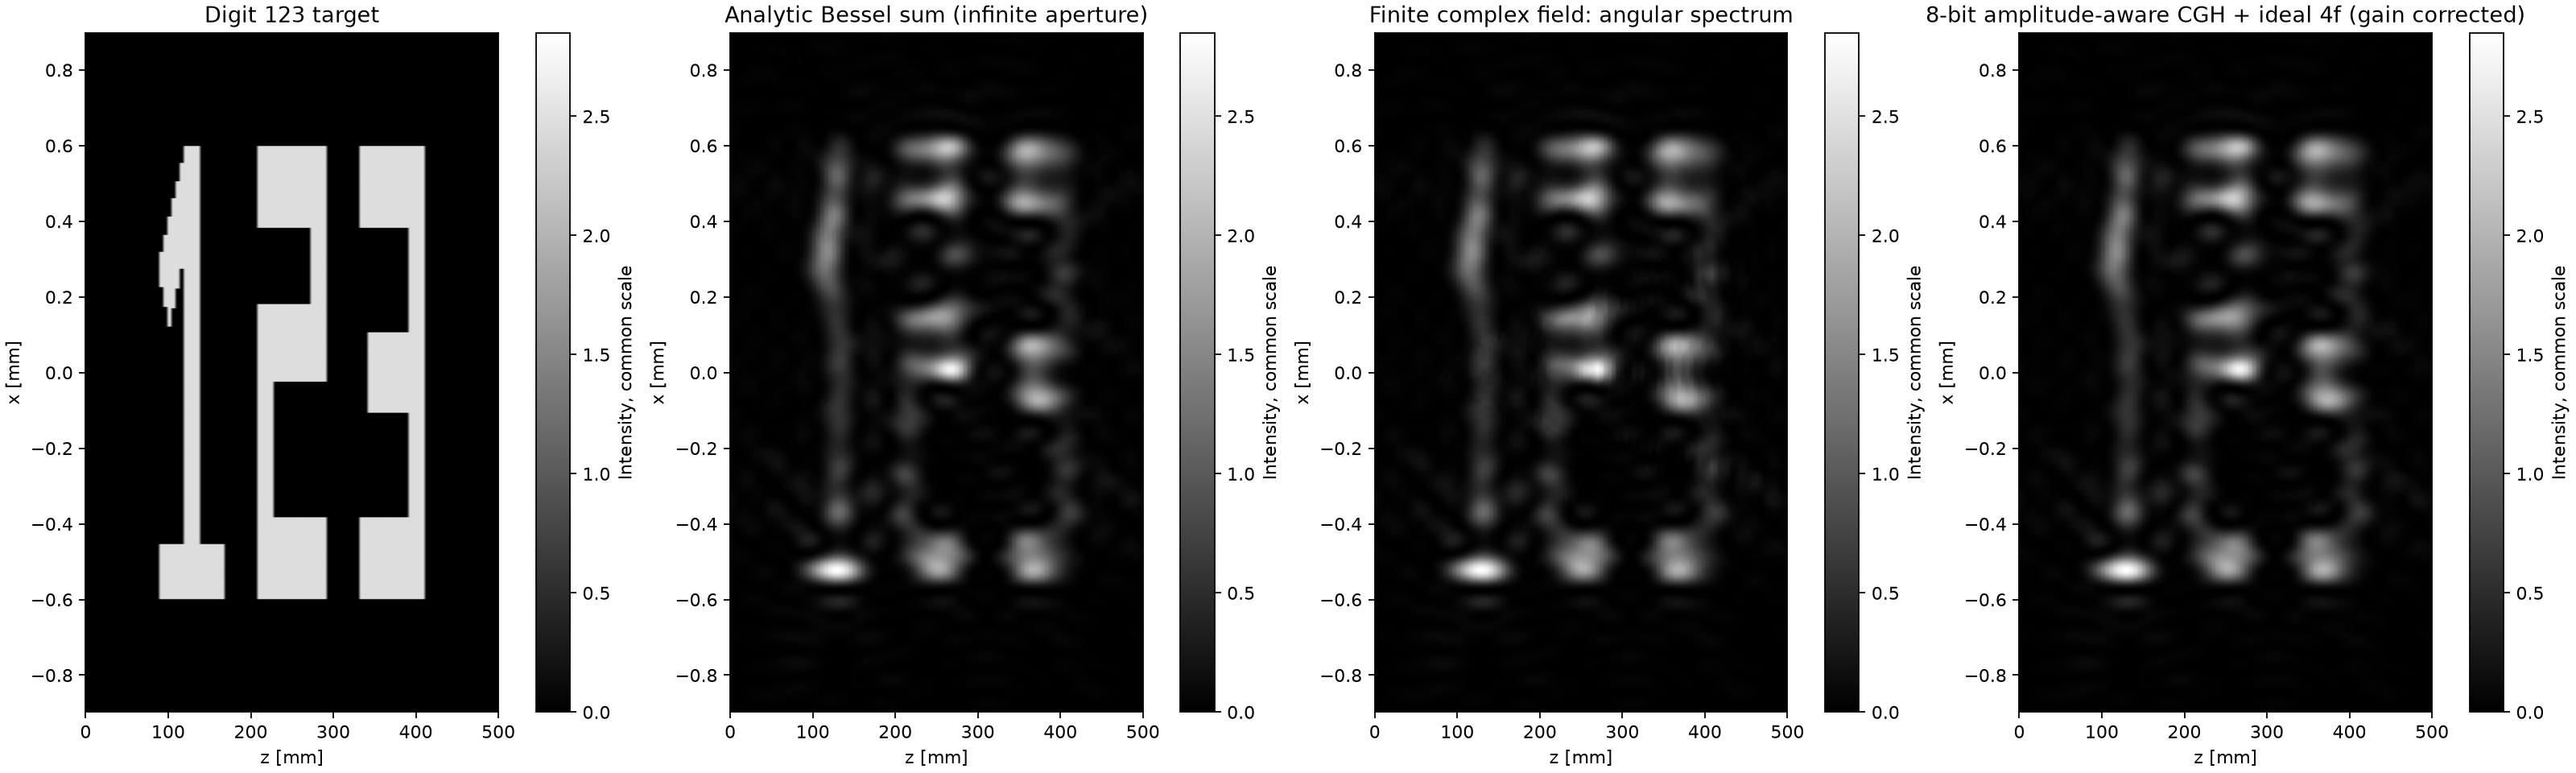

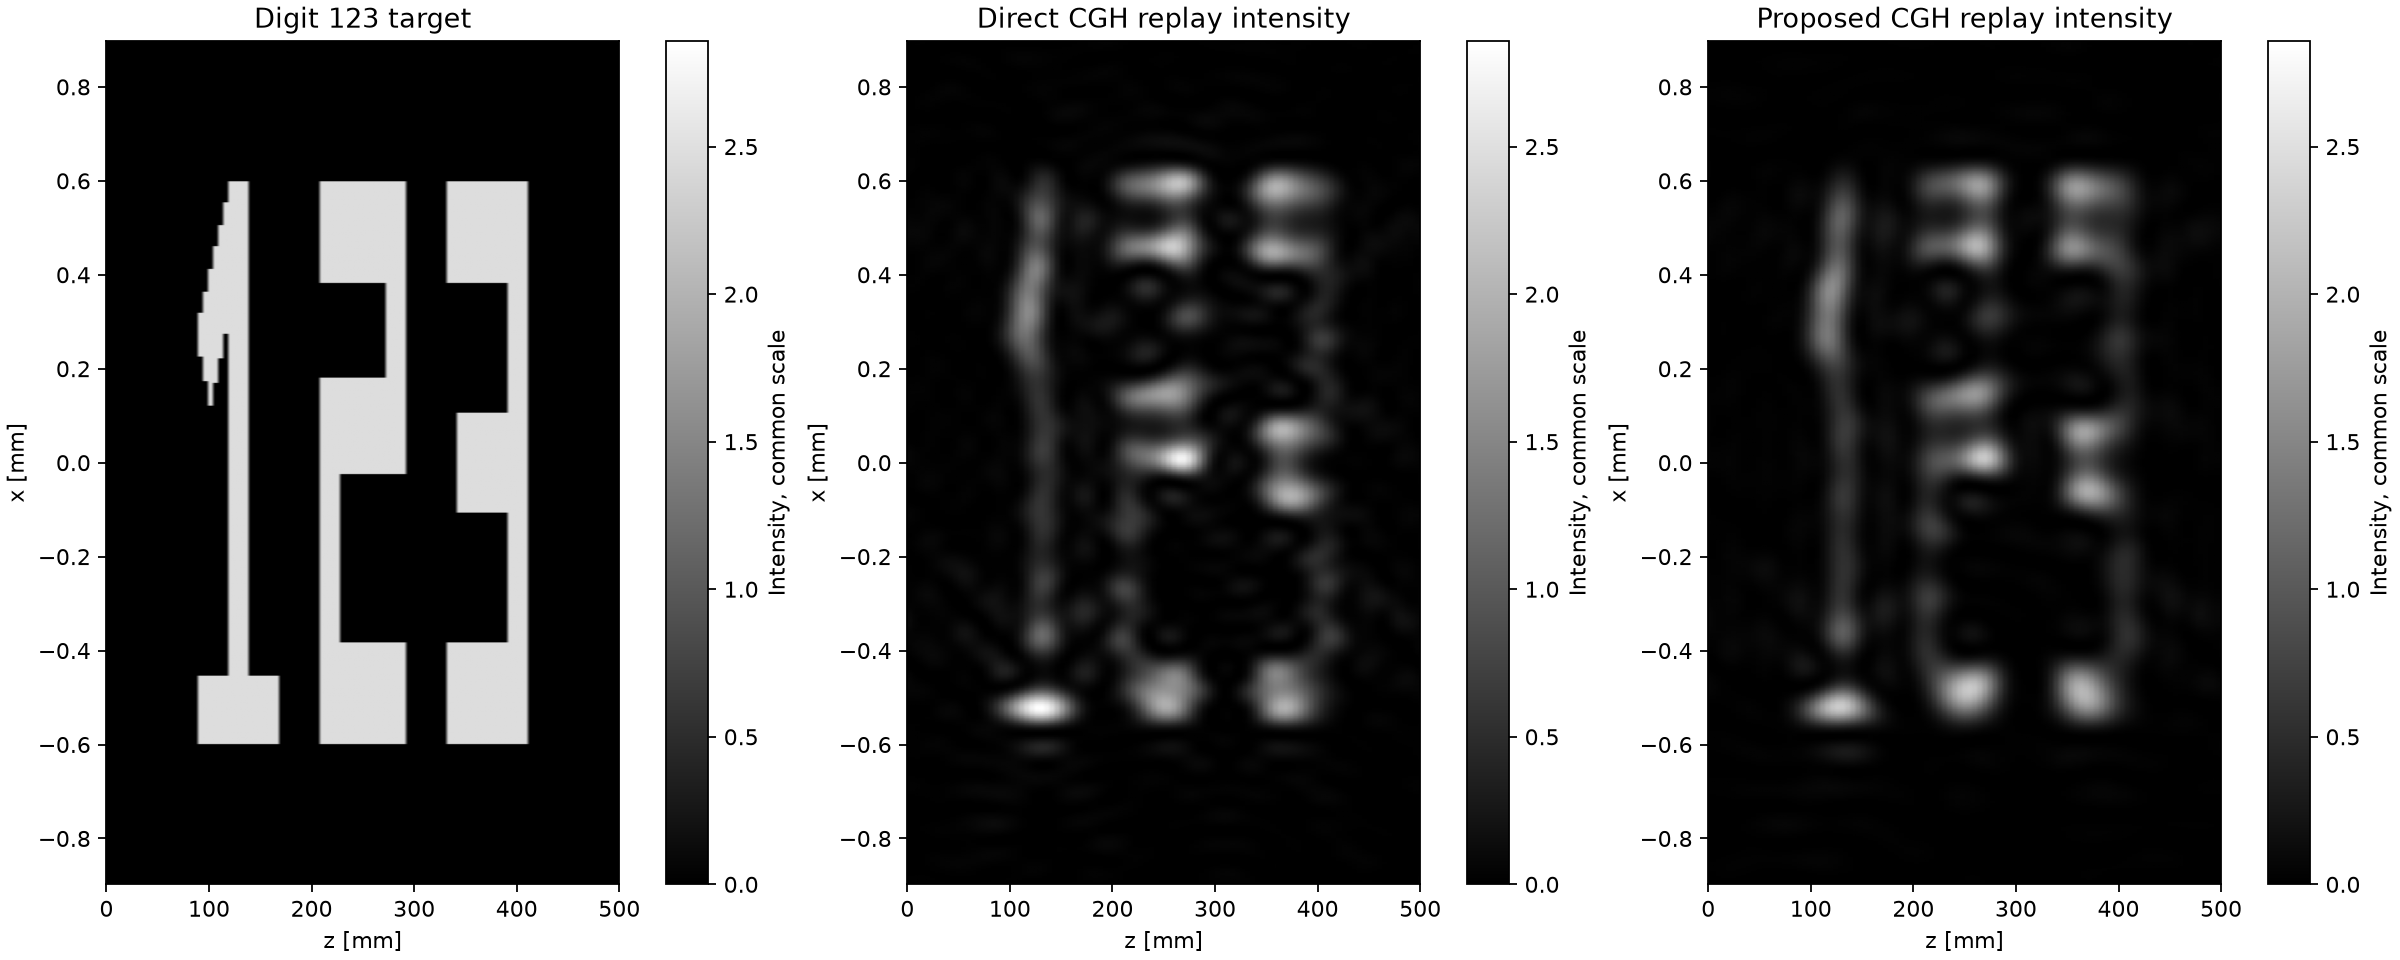

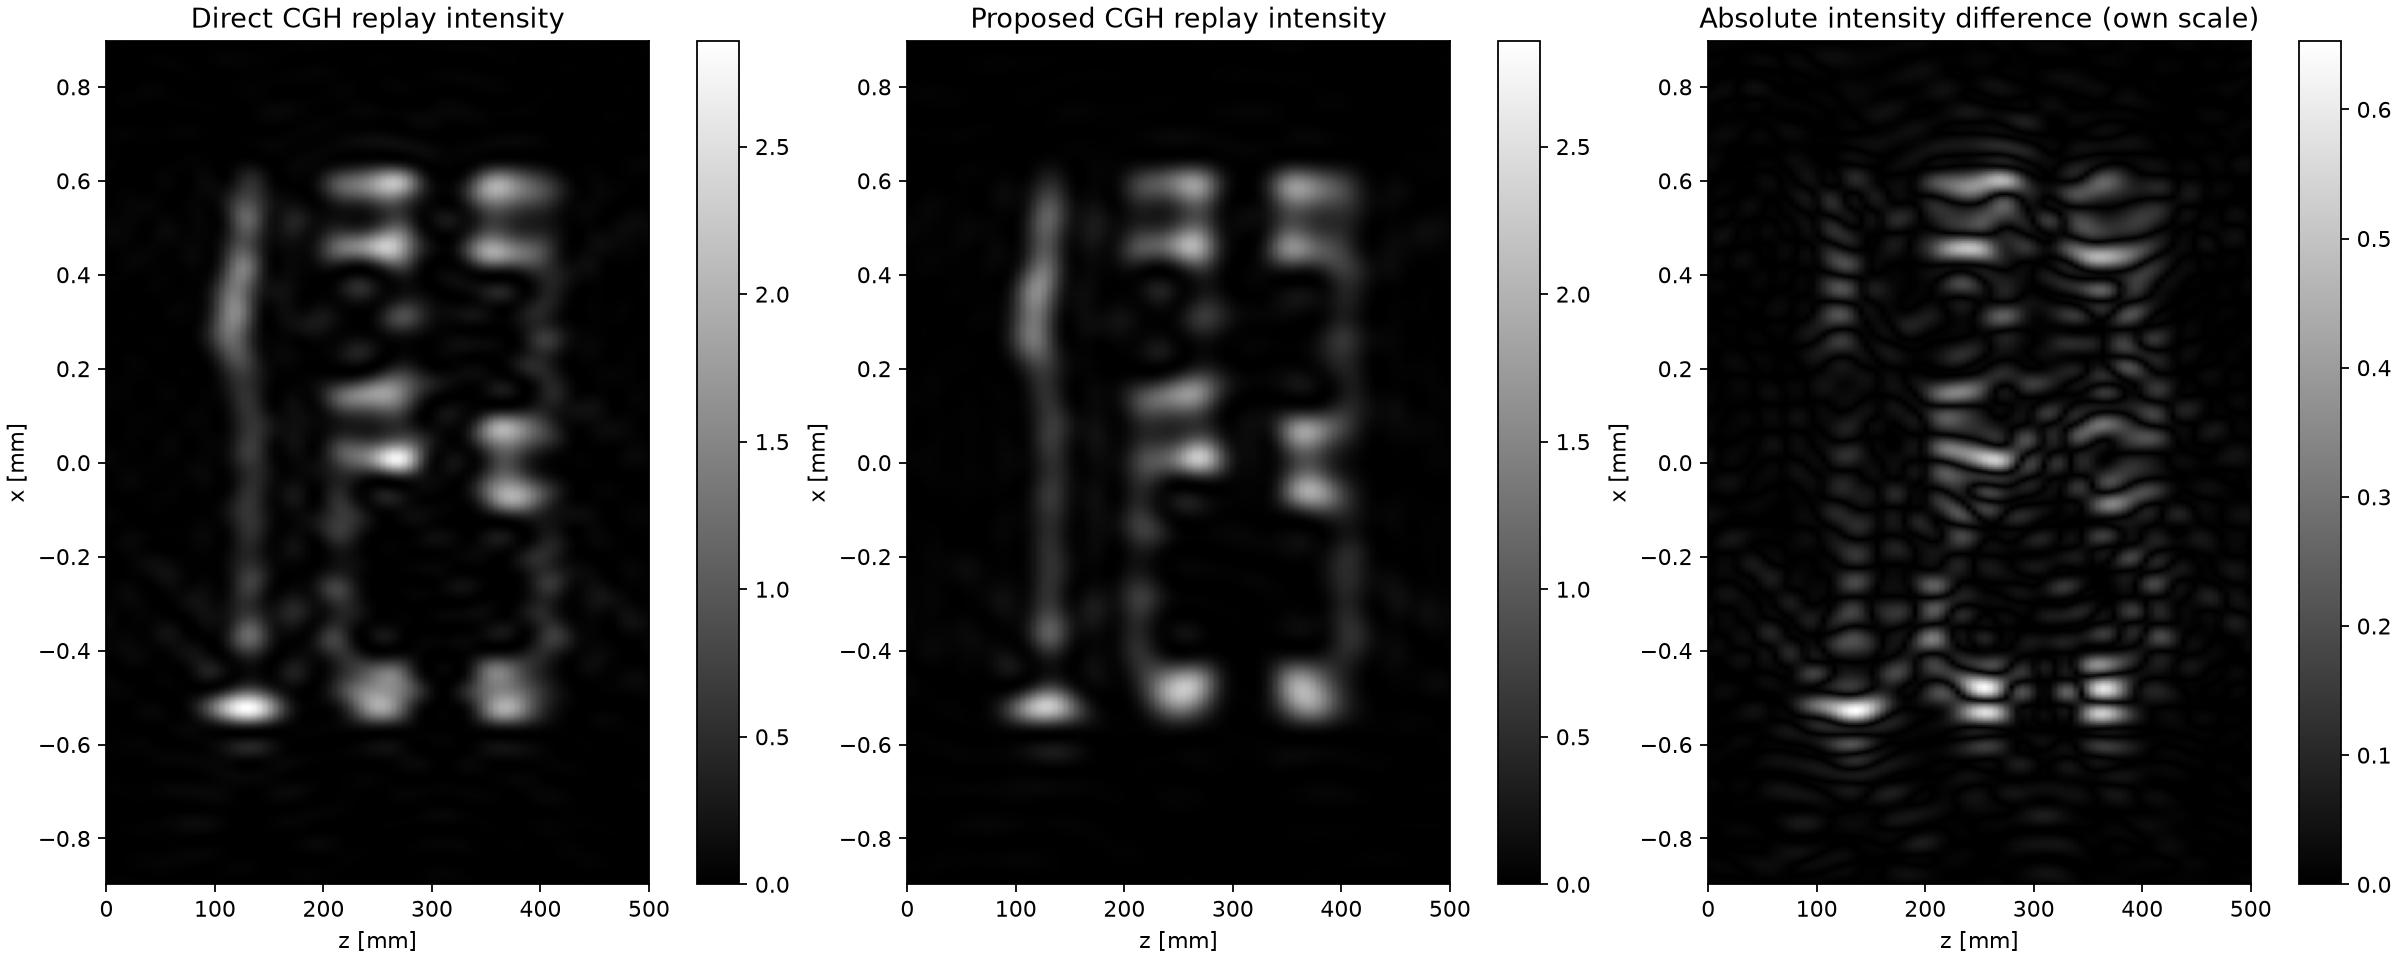

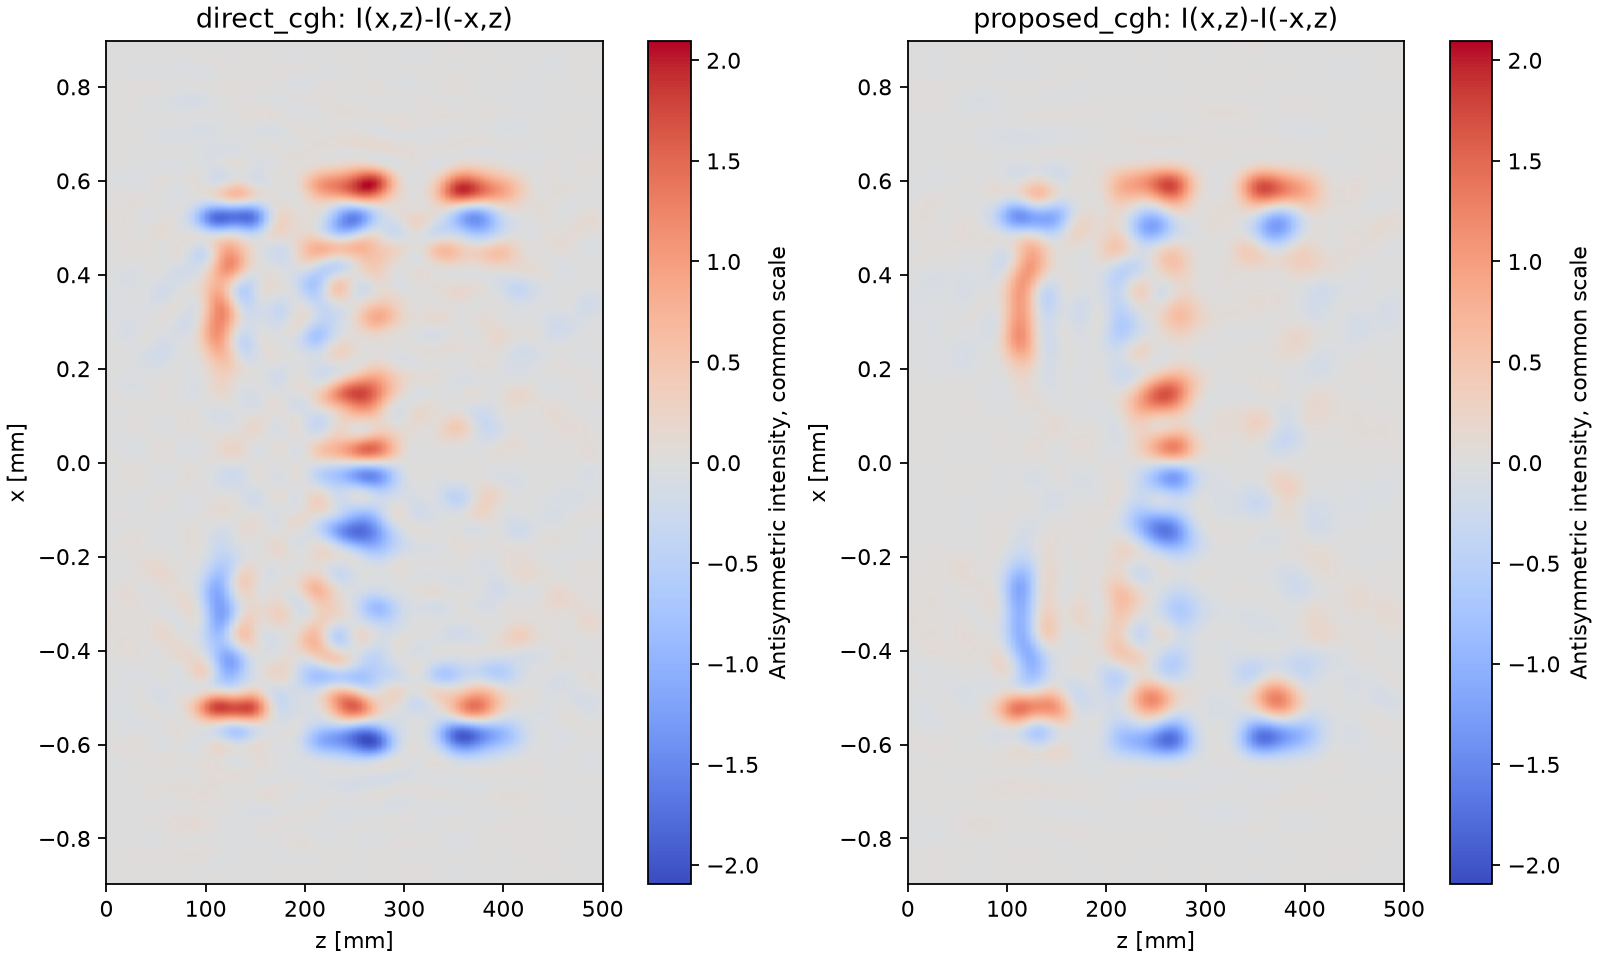

実際の非零Thread数: 16
Bessel項数: 240
提案法/直接法：CGH再生後: {'complex_relative_l2': 0.22680638287737576, 'intensity_relative_l2': 0.18977440260209125, 'ssim': 0.9047247512661697, 'psnr_db': 31.549941818144745, 'snr_db': 14.435247340636597}
直接法/目標: {'intensity_relative_l2': 0.7546817981525146, 'ssim': 0.3168894724602033, 'psnr_db': 9.821346531139309, 'snr_db': 2.4447224889026806}
提案法/目標: {'intensity_relative_l2': 0.7622042661917175, 'ssim': 0.3779918886890638, 'psnr_db': 9.735196536921256, 'snr_db': 2.358572494684629}
生成時間: {'direct_field_generation': 36.82950010000786, 'proposed_field_generation': {'thread_core_weighting_seconds': 0.0044781999895349145, 'shift_operator_seconds': 0.09247280002455227, 'shifted_core_sum_seconds': 0.0072026999841909856, 'spatial_factor_reconstruction_seconds': 0.021708500004024245, 'field_generation_seconds': 0.1260614000057103}, 'cgh_encode_and_ideal4f_replay': {'direct': 1.327285799998208, 'proposed': 1.3106893000076525}, 'all_four_propagation': 67.15893560000404}
CG

In [4]:
from IPython.display import Image, display
proposed.refresh_sheet_comparison_labels(proposed_dir)  # 保存強度から比較図だけ再描画。
display(Image(filename=str(theory_dir / 'digit1_sheet_comparison.png'), width=1300))
for filename in ('target_direct_proposed.png', 'cgh_sheet_comparison.png', 'asymmetry_comparison.png'):
    display(Image(filename=str(proposed_dir / filename), width=1200))
result = summaries['proposed']
print('実際の非零Thread数:', result['active_thread_count'])
print('Bessel項数:', result['nonzero_bessel_term_count'])
print('提案法/直接法：CGH再生後:', result['metrics']['cgh_sheet_proposed_vs_direct'])
print('直接法/目標:', result['metrics']['direct_cgh_sheet_vs_target'])
print('提案法/目標:', result['metrics']['proposed_cgh_sheet_vs_target'])
print('生成時間:', result['timings_seconds'])
print('CGH:', (proposed_dir / 'proposed_cgh_8bit.png').resolve())
print('センサー断面:', (proposed_dir / 'sensor_xy').resolve())
